In [1]:
!pip install catboost xgboost lightgbm gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 33.4 MB/s  0:00:02


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor, ExtraTreesRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [3]:
df = pd.read_csv("Apartments Prices Dataset.csv")
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000 EGP",120 m²,2 rooms,3 bathroom,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,"3,250,000 EGP",162 m²,3 rooms,2 bathroom,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,"2,650,000 EGP",122 m²,3 rooms,1 bathroom,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,"12,720,000 EGP",212 m²,4 rooms,3 bathroom,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,"5,898,000 EGP",135 m²,2 rooms,1 bathroom,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux


In [4]:
df.shape

(5578, 11)

In [5]:
df.columns

Index(['price', 'area_sqm', 'rooms', 'bathrooms', 'floor_level', 'year_built',
       'seller_type', 'view', 'price_per_sqm', 'payment_method',
       'finishing_type'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   price           5578 non-null   object
 1   area_sqm        5578 non-null   object
 2   rooms           5578 non-null   object
 3   bathrooms       5578 non-null   object
 4   floor_level     5578 non-null   object
 5   year_built      5578 non-null   int64 
 6   seller_type     5578 non-null   object
 7   view            5578 non-null   object
 8   price_per_sqm   5578 non-null   object
 9   payment_method  5578 non-null   object
 10  finishing_type  5578 non-null   object
dtypes: int64(1), object(10)
memory usage: 479.5+ KB


In [7]:
df.describe()

,year_built
count,5578.000000
mean,2022.327178
std,8.431095
min,1915.000000
25%,2023.000000
50%,2025.000000
75%,2026.000000
max,2037.000000


In [8]:
df.isnull().sum()

,0
price,0
area_sqm,0
rooms,0
bathrooms,0
floor_level,0
year_built,0
seller_type,0
view,0
price_per_sqm,0
payment_method,0


In [9]:
df.duplicated().sum()

np.int64(1489)

In [10]:
df = df.drop_duplicates()

In [11]:
df.shape

(4089, 11)

In [12]:
df["price"] = df["price"].str.replace(r"\D", "", regex=True).astype(float)
df["area_sqm"] = df["area_sqm"].str.replace(r"\D", "", regex=True).astype(float)
df["rooms"] = df["rooms"].str.extract(r"(\d+)")[0].astype(float)
df["bathrooms"] = df["bathrooms"].str.extract(r"(\d+)")[0].astype(float)
df["floor_level"] = df["floor_level"].replace("Ground", "0").astype(float)

In [13]:
df["seller_type"].value_counts()

,count
seller_type,
Broker,3539
Developer,335
Private Owner,164
Compound Developer,21
Cash,19
Cash or Installments,6
Installments,5


In [14]:
shifted = df["seller_type"].isin(["Cash", "Installments", "Cash or Installments"])
shifted.sum()

np.int64(30)

In [15]:
df.loc[shifted, "seller_type"] = df.loc[shifted, "price_per_sqm"]

In [16]:
df["seller_type"].value_counts()

,count
seller_type,
Broker,3555
Developer,341
Private Owner,172
Compound Developer,21


In [17]:
df["ppsqm"] = df["price"] / df["area_sqm"]
df["ppsqm"].describe()

,ppsqm
count,4089.000000
mean,42754.864121
std,28098.092667
min,4166.666667
25%,25000.000000
50%,36786.474684
75%,53906.250000
max,655172.413793


In [18]:
df = df[(df["ppsqm"] >= 5000) & (df["ppsqm"] <= 200000)]

In [19]:
df = df.drop(columns=["price_per_sqm", "ppsqm"])

In [20]:
df.loc[df["rooms"] > 6, "rooms"] = np.nan
df.loc[df["bathrooms"] > 6, "bathrooms"] = np.nan
df.loc[df["floor_level"] > 30, "floor_level"] = np.nan
df.loc[(df["area_sqm"] < 30) | (df["area_sqm"] > 600), "area_sqm"] = np.nan
df.loc[(df["year_built"] < 1960) | (df["year_built"] > 2030), "year_built"] = np.nan

In [21]:
df.isnull().sum()

,0
price,0
area_sqm,1
rooms,6
bathrooms,4
floor_level,2
year_built,6
seller_type,0
view,0
payment_method,0
finishing_type,0


In [22]:
df.shape

(4083, 10)

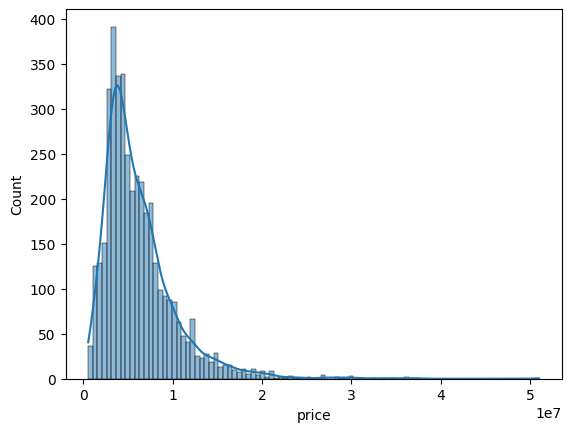

In [23]:
sns.histplot(df["price"], kde=True)
plt.show()

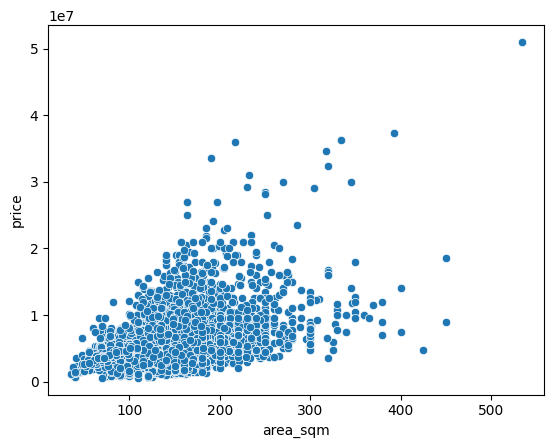

In [24]:
sns.scatterplot(x="area_sqm", y="price", data=df)
plt.show()

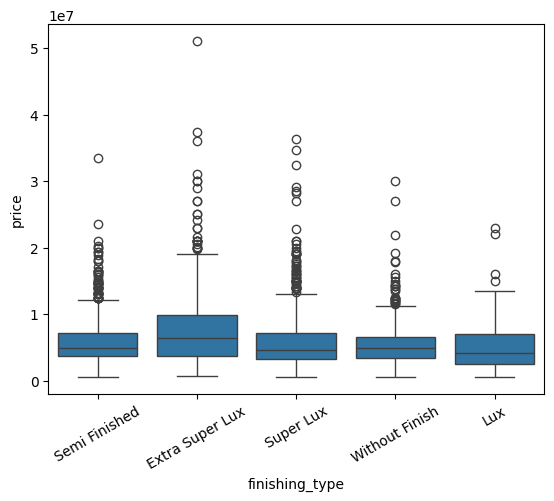

In [25]:
sns.boxplot(x="finishing_type", y="price", data=df)
plt.xticks(rotation=30)
plt.show()

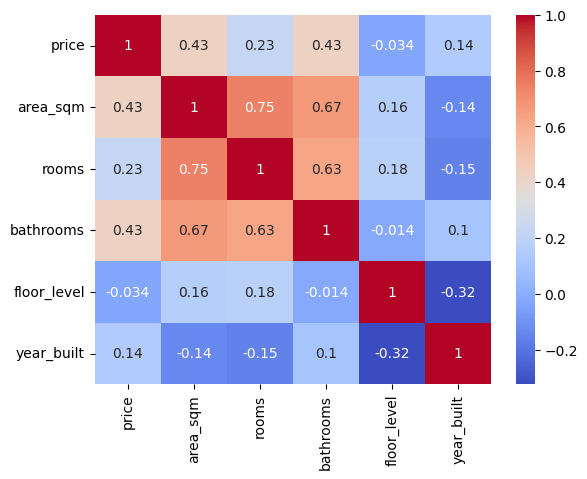

In [26]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.show()

In [27]:
finishing = {"Without Finish": 0, "Semi Finished": 1, "Lux": 2, "Super Lux": 3, "Extra Super Lux": 4}
df["finishing_type"] = df["finishing_type"].map(finishing)

In [28]:
df_clean = df.copy()

In [29]:
onehot_cols = ["seller_type", "view", "payment_method"]
df = pd.get_dummies(df, columns=onehot_cols, drop_first=True, dtype=int)

In [30]:
X = df.drop(columns="price")

In [31]:
y = np.log1p(df["price"])

In [32]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [33]:
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)

In [34]:
X_train.isnull().sum().sum()

np.int64(0)

In [35]:
num_cols = [c for c in X_train.columns if X_train[c].nunique() > 2]

In [36]:
skewed = [c for c in num_cols if abs(X_train[c].skew()) > 0.75]
X_train[skewed] = np.log1p(X_train[skewed])
X_test[skewed] = np.log1p(X_test[skewed])

In [37]:
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [38]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [39]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

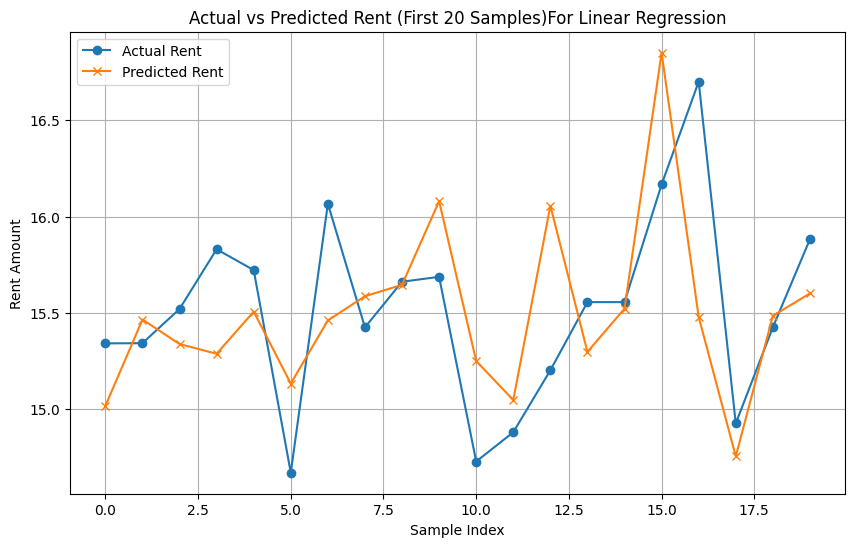

  7%|▋         | 1/15 [00:00<00:13,  1.06it/s]

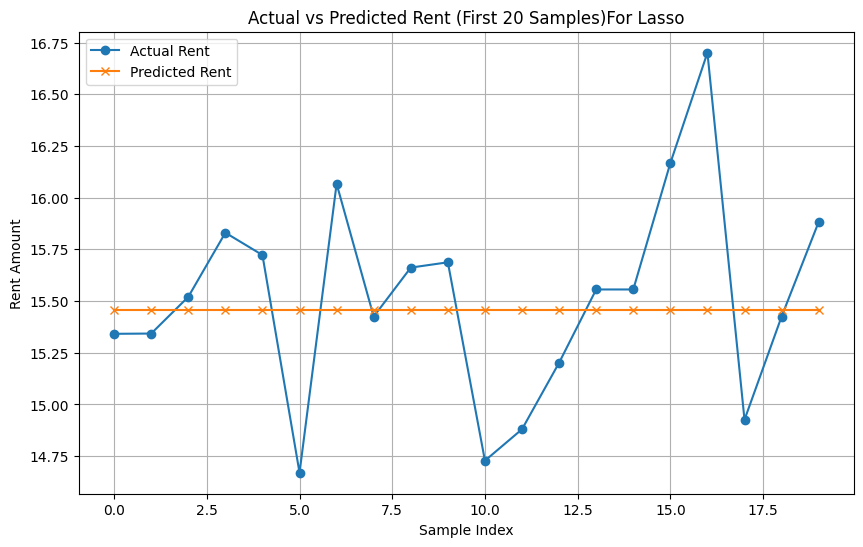

 13%|█▎        | 2/15 [00:01<00:10,  1.20it/s]

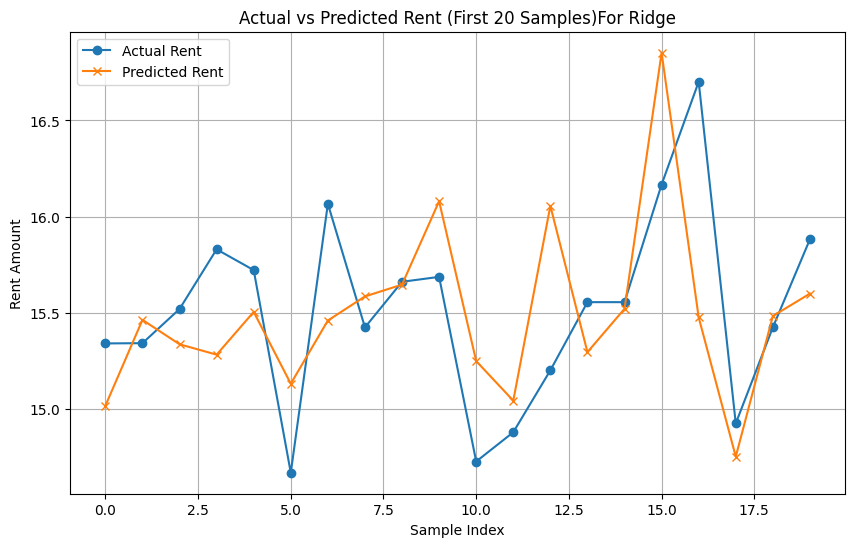

 20%|██        | 3/15 [00:02<00:08,  1.39it/s]

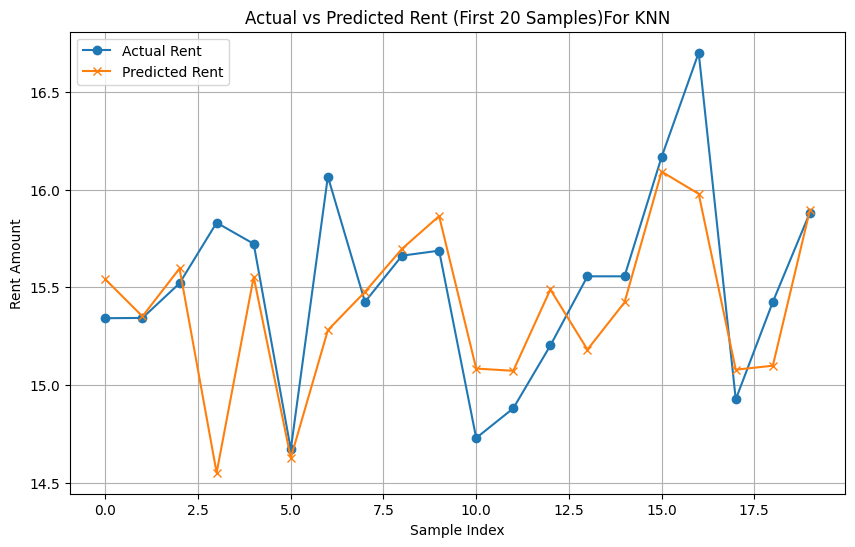

 27%|██▋       | 4/15 [00:03<00:10,  1.01it/s]

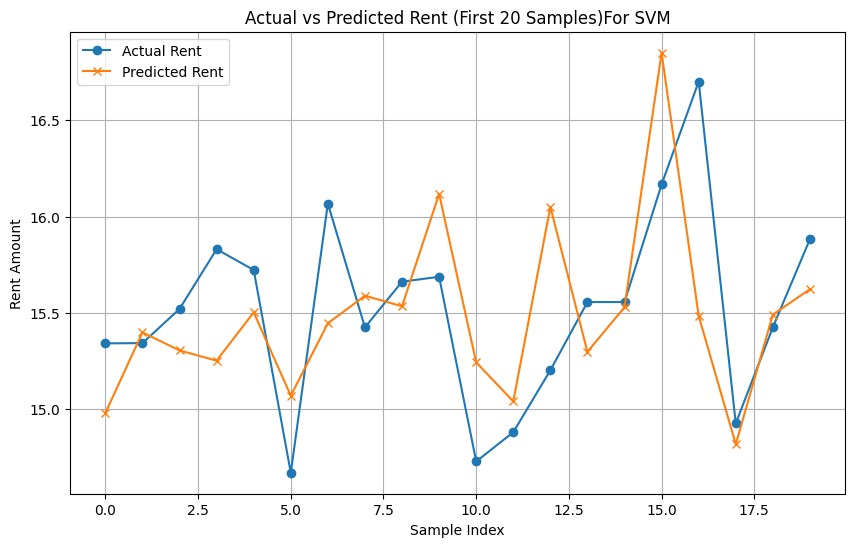

 33%|███▎      | 5/15 [01:08<03:59, 23.98s/it]

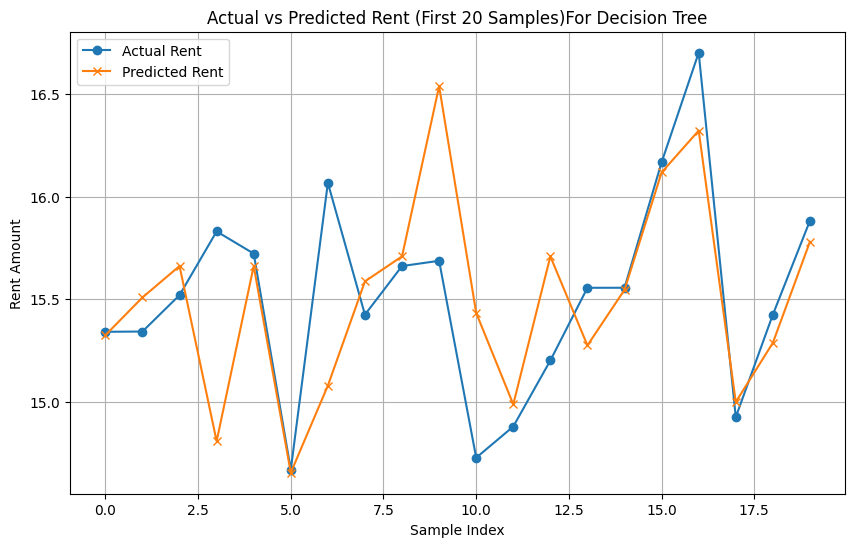

 40%|████      | 6/15 [01:08<02:23, 15.94s/it]

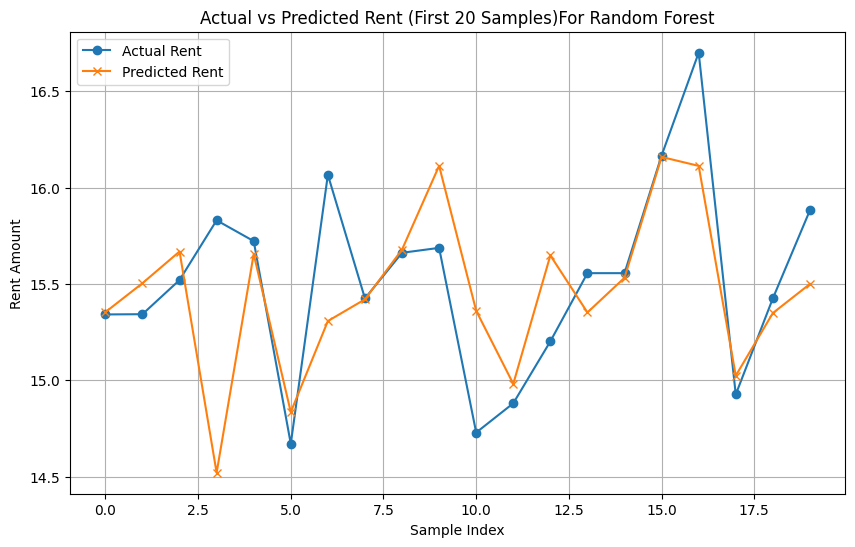

 47%|████▋     | 7/15 [01:09<01:28, 11.01s/it]

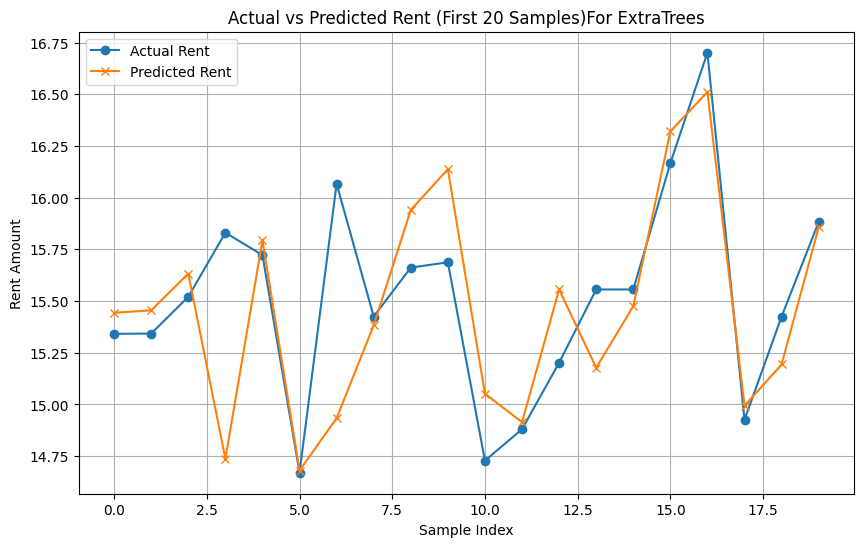

 53%|█████▎    | 8/15 [01:11<00:55,  7.99s/it]

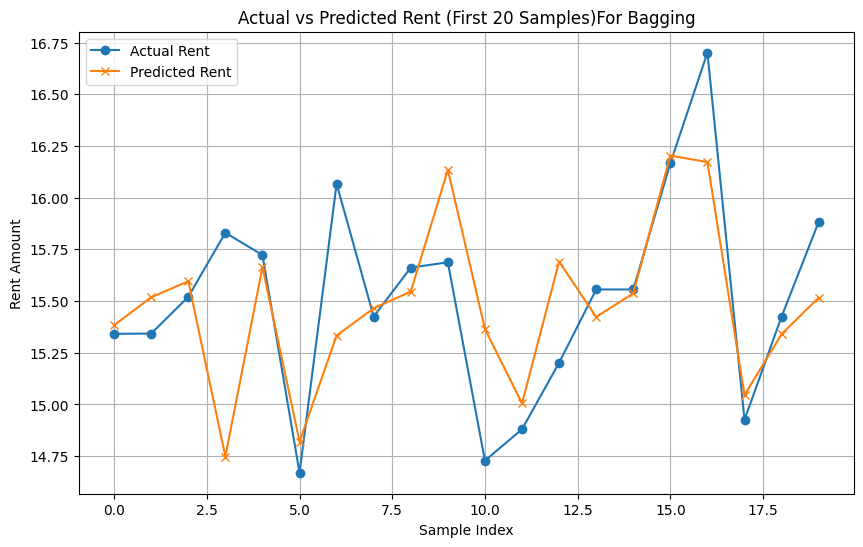

 60%|██████    | 9/15 [01:11<00:34,  5.72s/it]

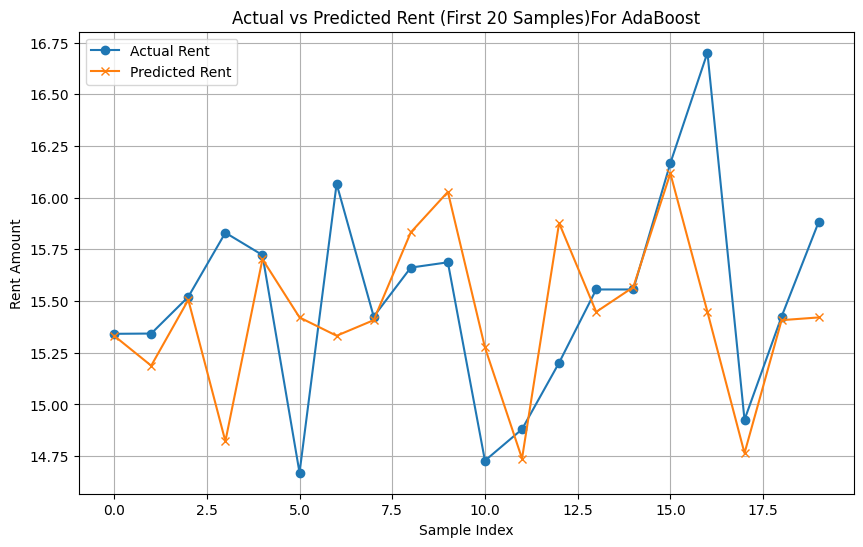

 67%|██████▋   | 10/15 [01:12<00:20,  4.05s/it]

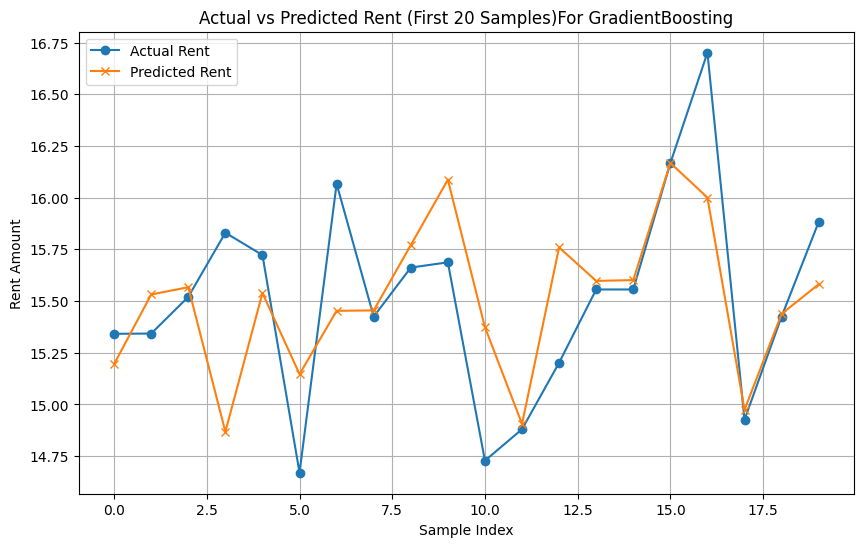

 73%|███████▎  | 11/15 [01:12<00:11,  2.99s/it]

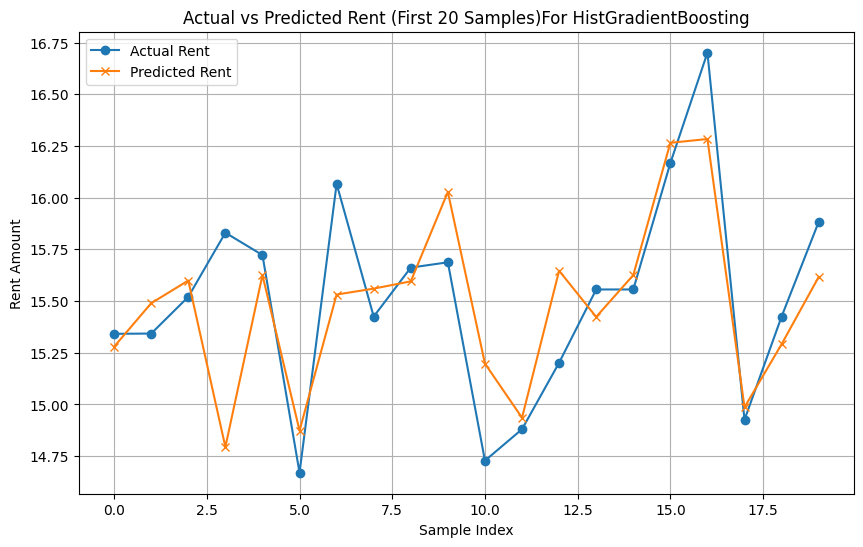

 80%|████████  | 12/15 [01:13<00:06,  2.26s/it]

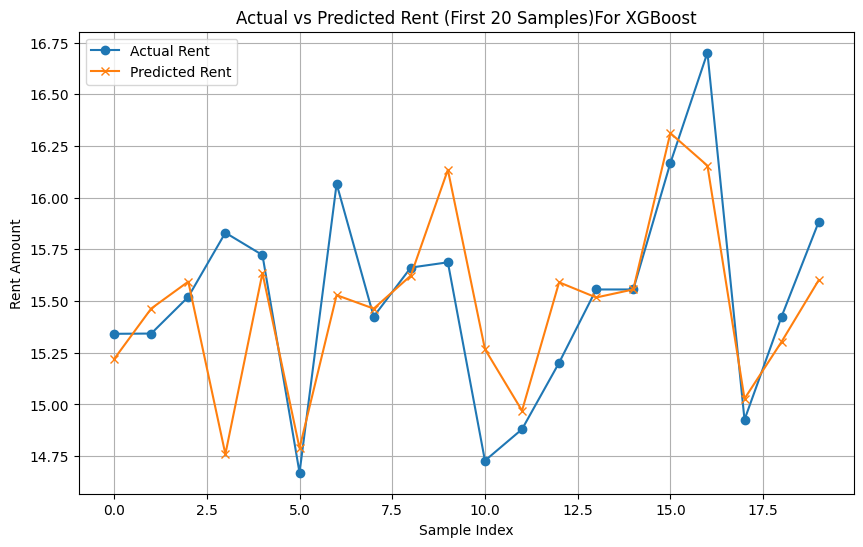

 87%|████████▋ | 13/15 [01:13<00:03,  1.75s/it]

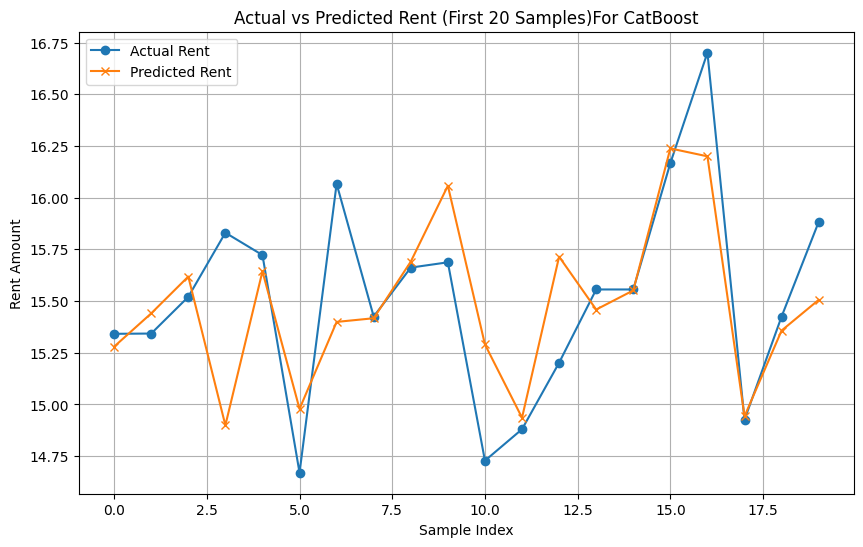

 93%|█████████▎| 14/15 [01:14<00:01,  1.35s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001035 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 310
[LightGBM] [Info] Number of data points in the train set: 3266, number of used features: 19
[LightGBM] [Info] Start training from score 15.455143


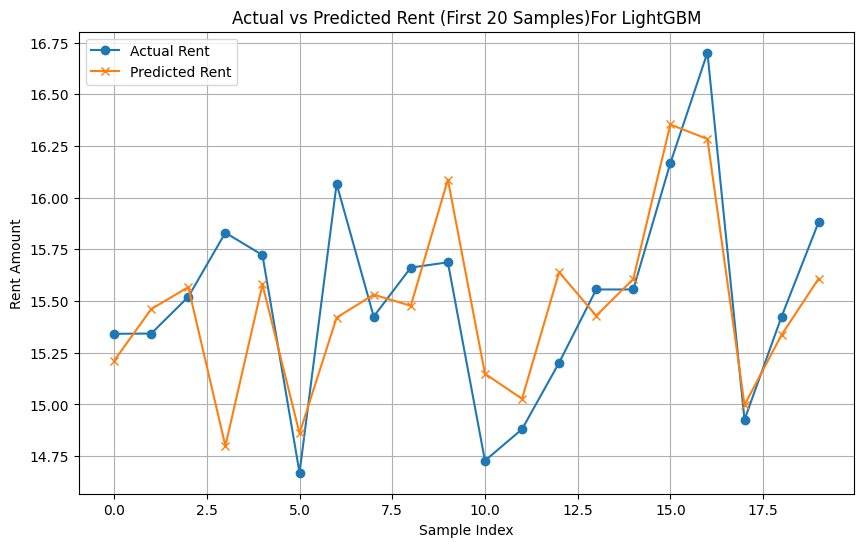

100%|██████████| 15/15 [01:14<00:00,  4.98s/it]


In [40]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [41]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [42]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [43]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [44]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
XGBoost,0.210041,0.268440,0.079969,0.123811,0.282788,0.351868,0.785737,0.665375
HistGradientBoosting,0.221896,0.271524,0.085697,0.126270,0.292740,0.355345,0.770390,0.658729
LightGBM,0.223379,0.270740,0.087081,0.126835,0.295095,0.356139,0.766681,0.657203
Bagging,0.219545,0.278338,0.082820,0.132738,0.287784,0.364333,0.778098,0.641248
Random Forest,0.218032,0.277897,0.082512,0.134249,0.287249,0.366400,0.778923,0.637164
CatBoost,0.277983,0.286486,0.129840,0.135649,0.360333,0.368305,0.652116,0.633381
Stacking,0.198838,0.270740,0.081802,0.126835,0.286011,0.356139,0.780825,0.623166
Simple Voting,0.148010,0.270740,0.036331,0.126835,0.190608,0.356139,0.902656,0.612353
Voting,0.148010,0.270740,0.036331,0.126835,0.190608,0.356139,0.902656,0.612353
ExtraTrees,0.008051,0.272891,0.001935,0.145678,0.043986,0.381678,0.994816,0.606276


<Axes: >

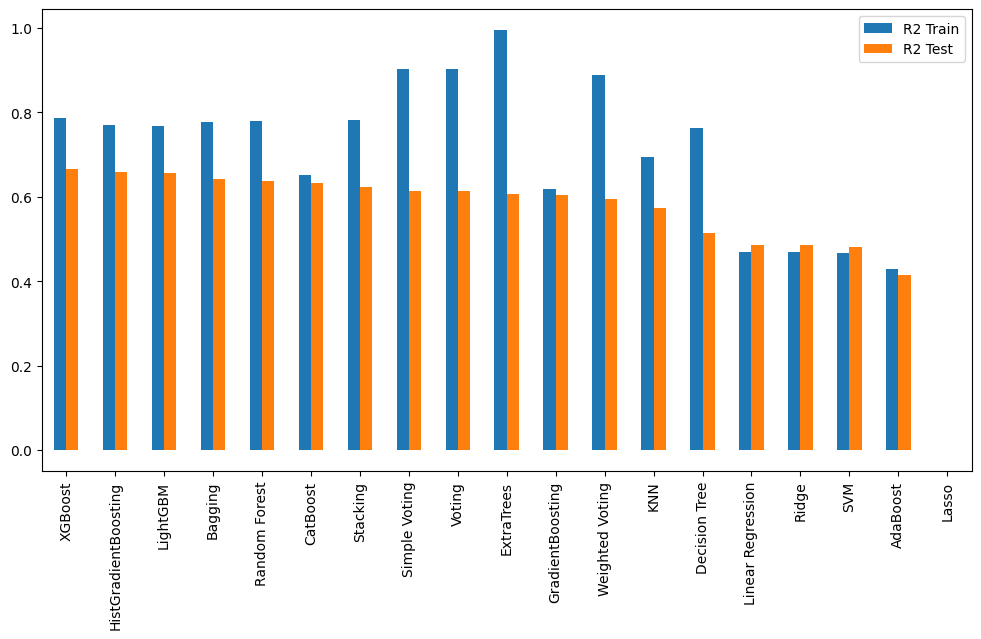

In [45]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

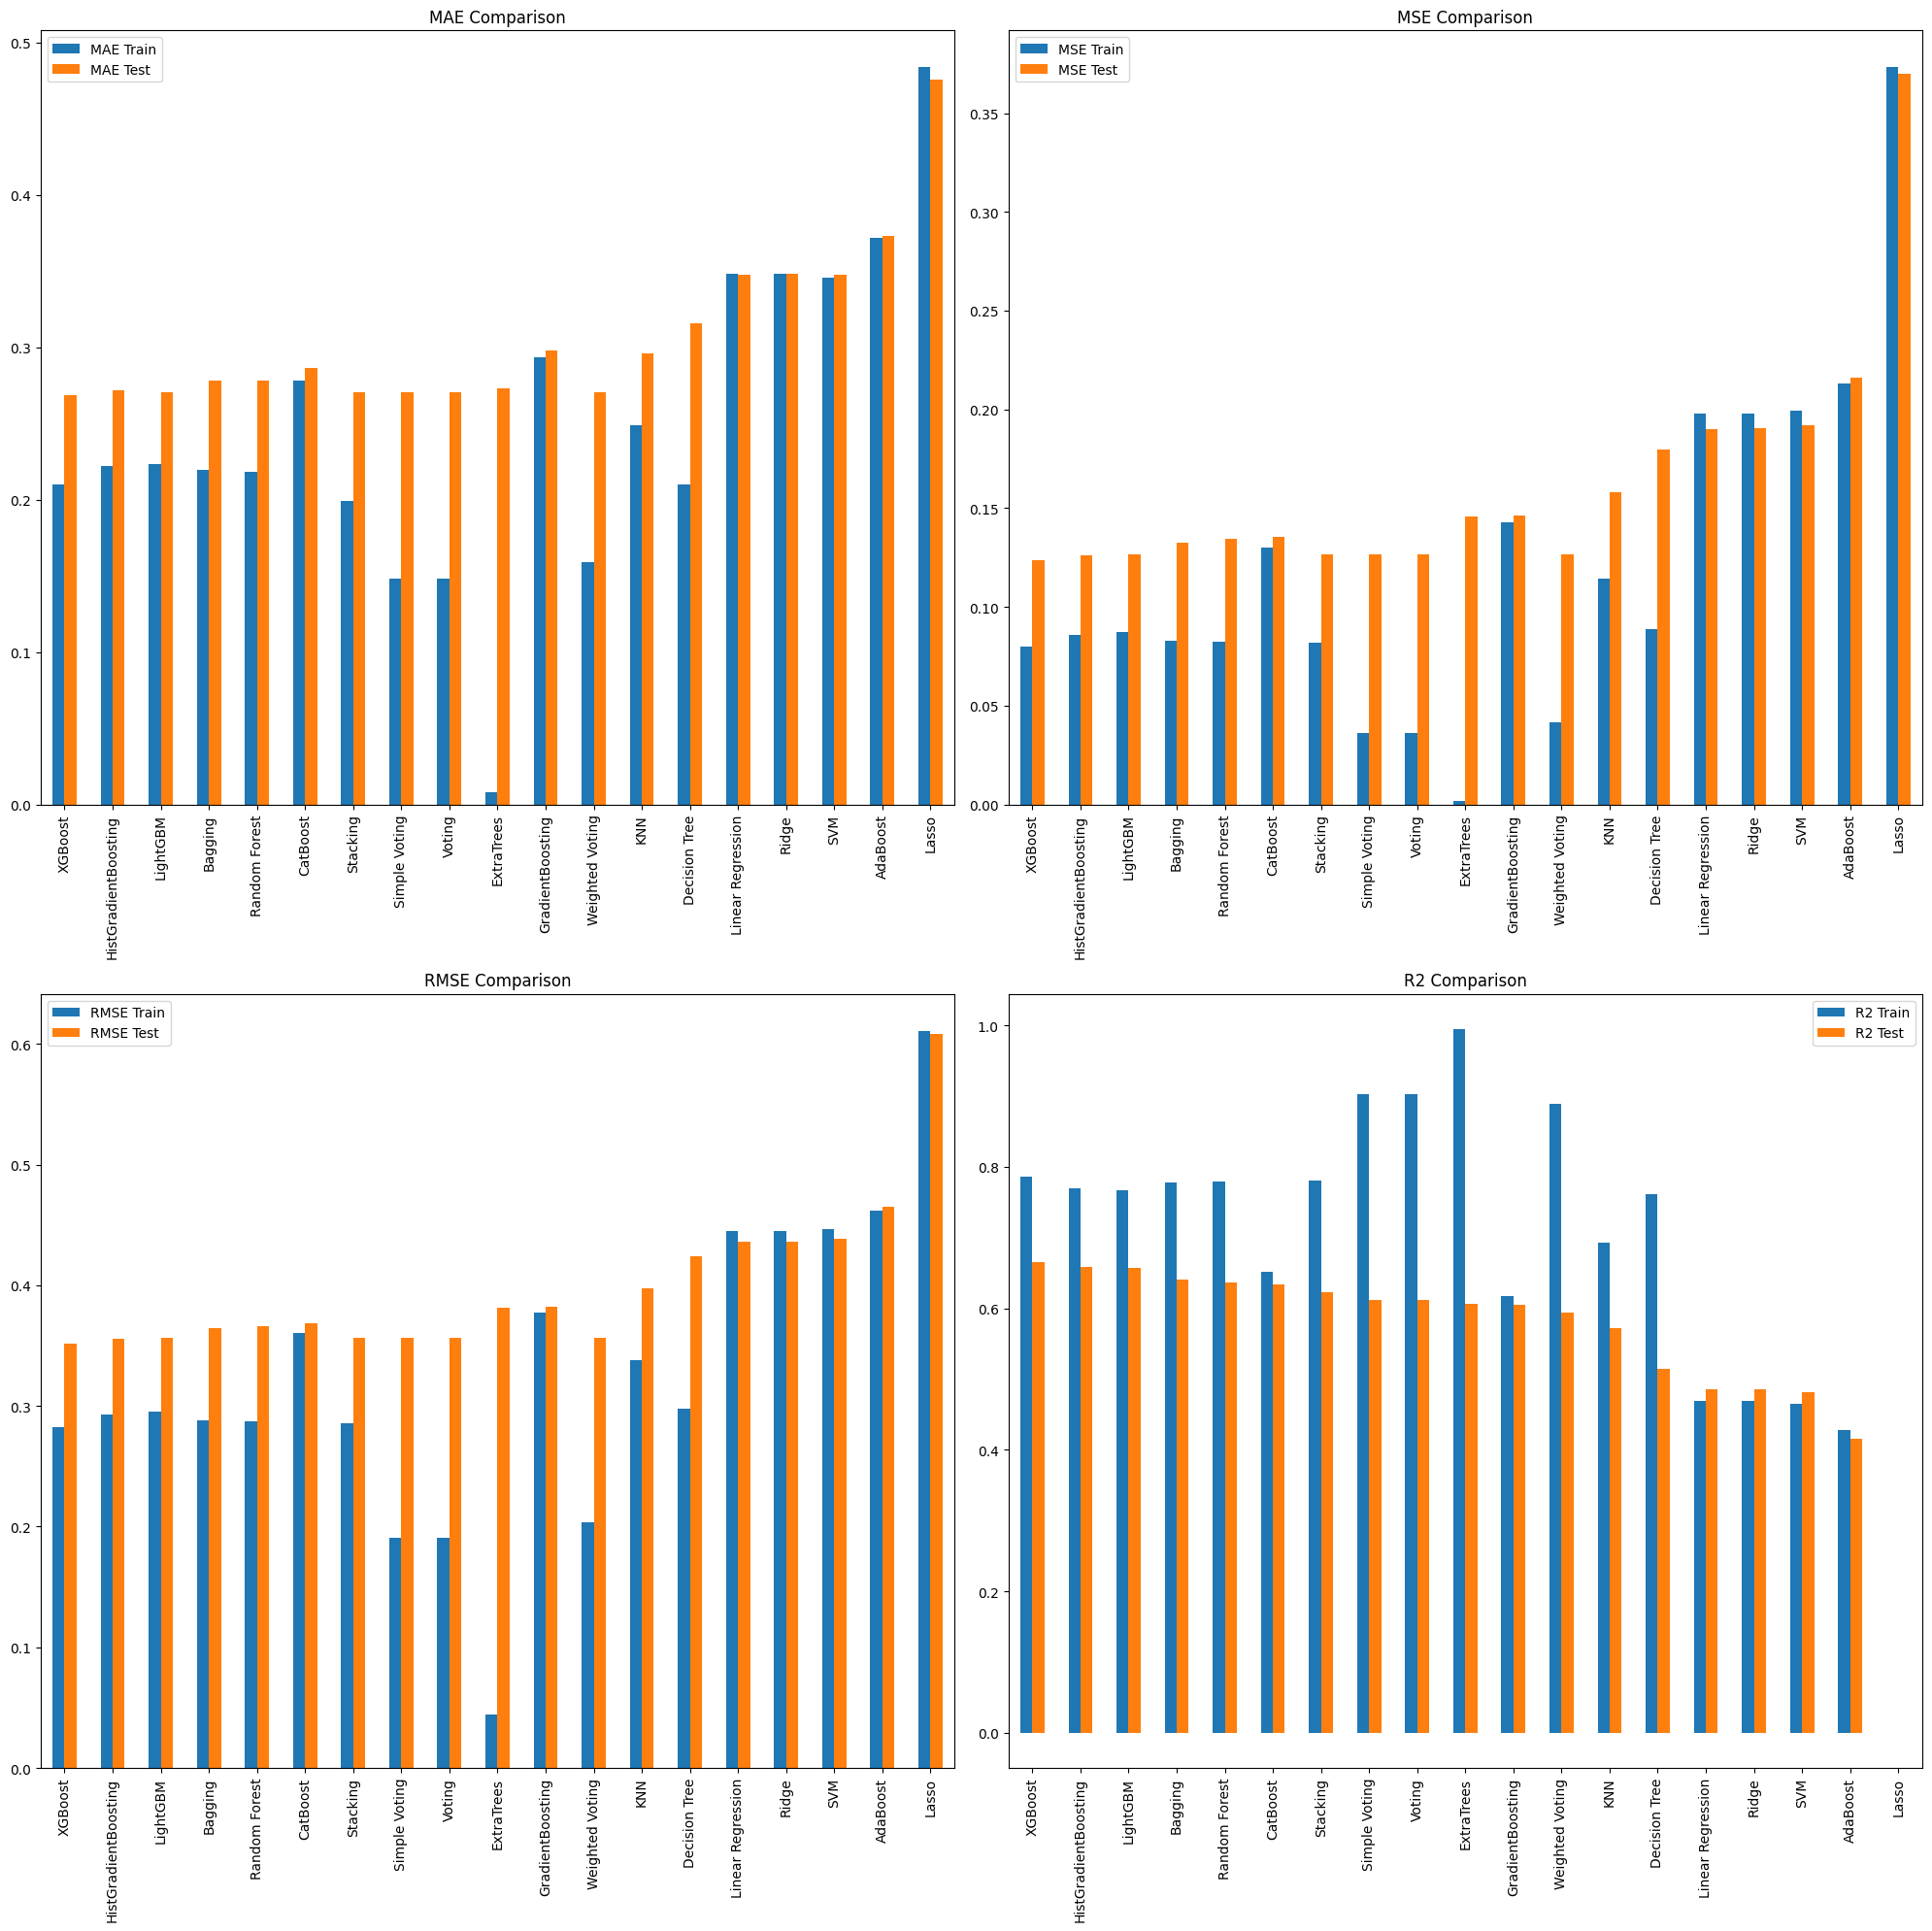

In [46]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

In [47]:
import gradio as gr


def predict_price(area, rooms, bathrooms, floor, year_built, seller, view, payment, finish):
    if None in (area, rooms, bathrooms, floor, year_built, seller, view, payment, finish):
        return " "

    row = pd.DataFrame([{
        "area_sqm": area, "rooms": rooms, "bathrooms": bathrooms, "floor_level": floor,
        "year_built": year_built, "seller_type": seller, "view": view,
        "payment_method": payment, "finishing_type": finishing[finish],
    }])


    row = pd.get_dummies(row, columns=onehot_cols)
    row = row.reindex(columns=X.columns, fill_value=0).astype(float)


    row[skewed] = np.log1p(row[skewed])
    row[num_cols] = scaler.transform(row[num_cols])

    price = np.expm1(best_model.predict(row))[0]
    return f"Estimated Price: {price:,.0f} EGP"


demo = gr.Interface(
    fn=predict_price,
    inputs=[
        gr.Number(label="Area (sqm)", value=150),
        gr.Dropdown(["1", "2", "3", "4", "5"], label="Rooms", value="3"),
        gr.Dropdown(["1", "2", "3", "4", "5"], label="Bathrooms", value="2"),
        gr.Number(label="Floor (0 = Ground)", value=3, precision=0),
        gr.Number(label="Year Built (or delivery year)", value=2025, precision=0),
        gr.Dropdown(sorted(df_clean["seller_type"].unique()), label="Seller Type", value="Broker"),
        gr.Dropdown(sorted(df_clean["view"].unique()), label="View", value="Main Street"),
        gr.Dropdown(sorted(df_clean["payment_method"].unique()), label="Payment Method", value="Cash"),
        gr.Dropdown(list(finishing.keys()), label="Finishing Type", value="Super Lux"),
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="Apartment Price Prediction App",
    description="Enter the apartment details to estimate its price.",
)

demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7bf2f63e9065b76b25.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
